# 全臺北市12區：熱點分析與政府工作分配

## 結論

本次覆蓋全部12區，公館只是一個案例。保存1,821站，主分析1,790個啟用有效站；12區各3個首輪查核錨點共36處，校區分類另列3處。這是全市分層查核與政府分工規劃，不是新垃圾桶配置或已確認的垃圾熱點。

七月檔有日期缺口；**實際固定期間為2026年7月31個日曆日，其中7/10、7/11列為品質標記日。** 活動是借還端點，不是人數、垃圾量或完整月需求。

## 範圍、資料與規則

- 規則在城市級運算前固定於 `protocol.md`。全站快照、七月借還、2026街道及場所清冊、2024反例、既有回饋彙總的來源與雜湊見 `manifest.json`。
- 各區按觀測活動選3點，同區點間至少300m直線；校區另列。這是首輪查核額度，不是需求或預算均分。完整逐站結果保留。
- 比較150/500m門檻及排除7/10、7/11的結果。未配對／無觀測保持未知，不能當零需求。分區沿來源sarea，沒有地籍或行政區界判定。
- 街道681列與場所130列不能相加成桶數；北投0街道列、南港4列是補查清冊的理由。回饋是篩選樣本，非人口發生率、無站點級連結。
- 原始ZIP保存在交付根目錄`raw/202607-youbike.zip`，整包移動可重跑，或設`TAIPEI_ARCHIVE`。先安裝`requirements-analysis.txt`；在本notebook目錄執行。

In [1]:
import os,json,io,contextlib
from pathlib import Path
from IPython.display import display,HTML,Image
from analyze import ROOT,main
from validate import validate
m=json.loads((ROOT/'manifest.json').read_text())
portable=ROOT.parents[1]/'raw/202607-youbike.zip'
archive=Path(os.environ.get('TAIPEI_ARCHIVE',str(portable if portable.exists() else m['trip_archive']['retained_archive'])))
with contextlib.redirect_stdout(io.StringIO()):
    summary=main(archive)
    receipt=validate()
print('Scope:',summary['scope'])
print('Raw rows:',summary['totals']['raw_rows'])
print('All station counts reconciled:',receipt['all_station_counts_reconciled'])
print('Unknown observation stations:',sum(d['unknown_stations'] for d in summary['districts']))

Scope: 12 districts plus NTU campus category
Raw rows: 7596992
All station counts reconciled: 1821
Unknown observation stations: 47


## 12區活動與清冊覆蓋

各區小計是活動量，不是垃圾需求或問題嚴重度。校區獨立序列避免重複加總；跨日期來源不能當同步現況。

來源分類,啟用有效站,已觀測站,端點活動,街道列,場所列,平日活動時段,週末活動時段
松山區,108,107,"1,255,794",55,7,18–19,18–19
信義區,129,127,"1,711,503",60,18,18–19,17–18
大安區,214,210,"2,926,122",47,18,18–19,18–19
中山區,200,195,"1,809,481",50,16,18–19,18–19
中正區,138,137,"1,351,594",83,16,18–19,18–19
大同區,85,84,"853,180",22,14,18–19,18–19
萬華區,94,91,"698,711",82,3,18–19,18–19
文山區,124,120,"555,429",51,9,18–19,18–19
南港區,124,121,"745,743",4,5,18–19,17–18
內湖區,226,221,"941,880",85,7,8–9,17–18


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


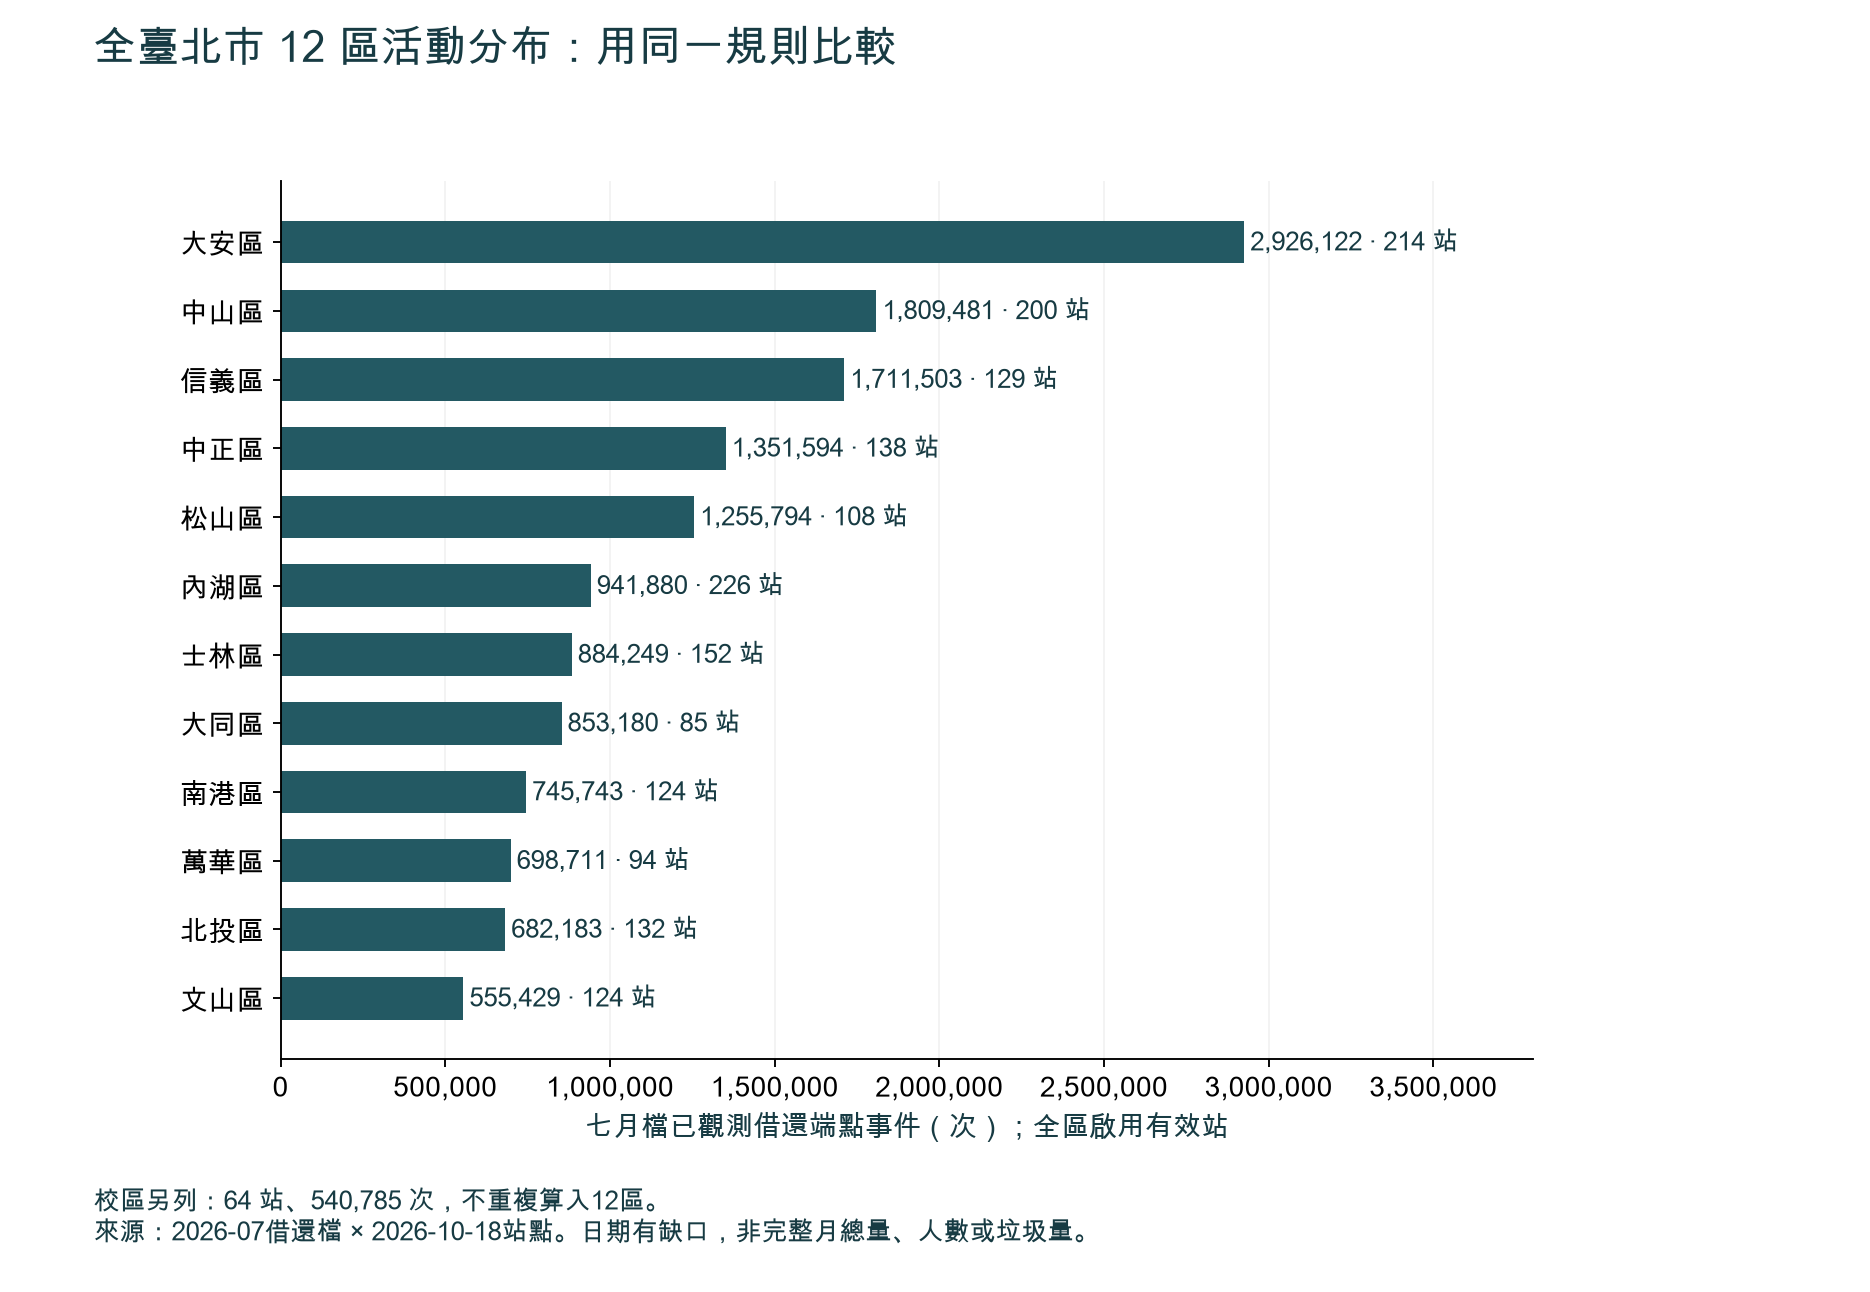

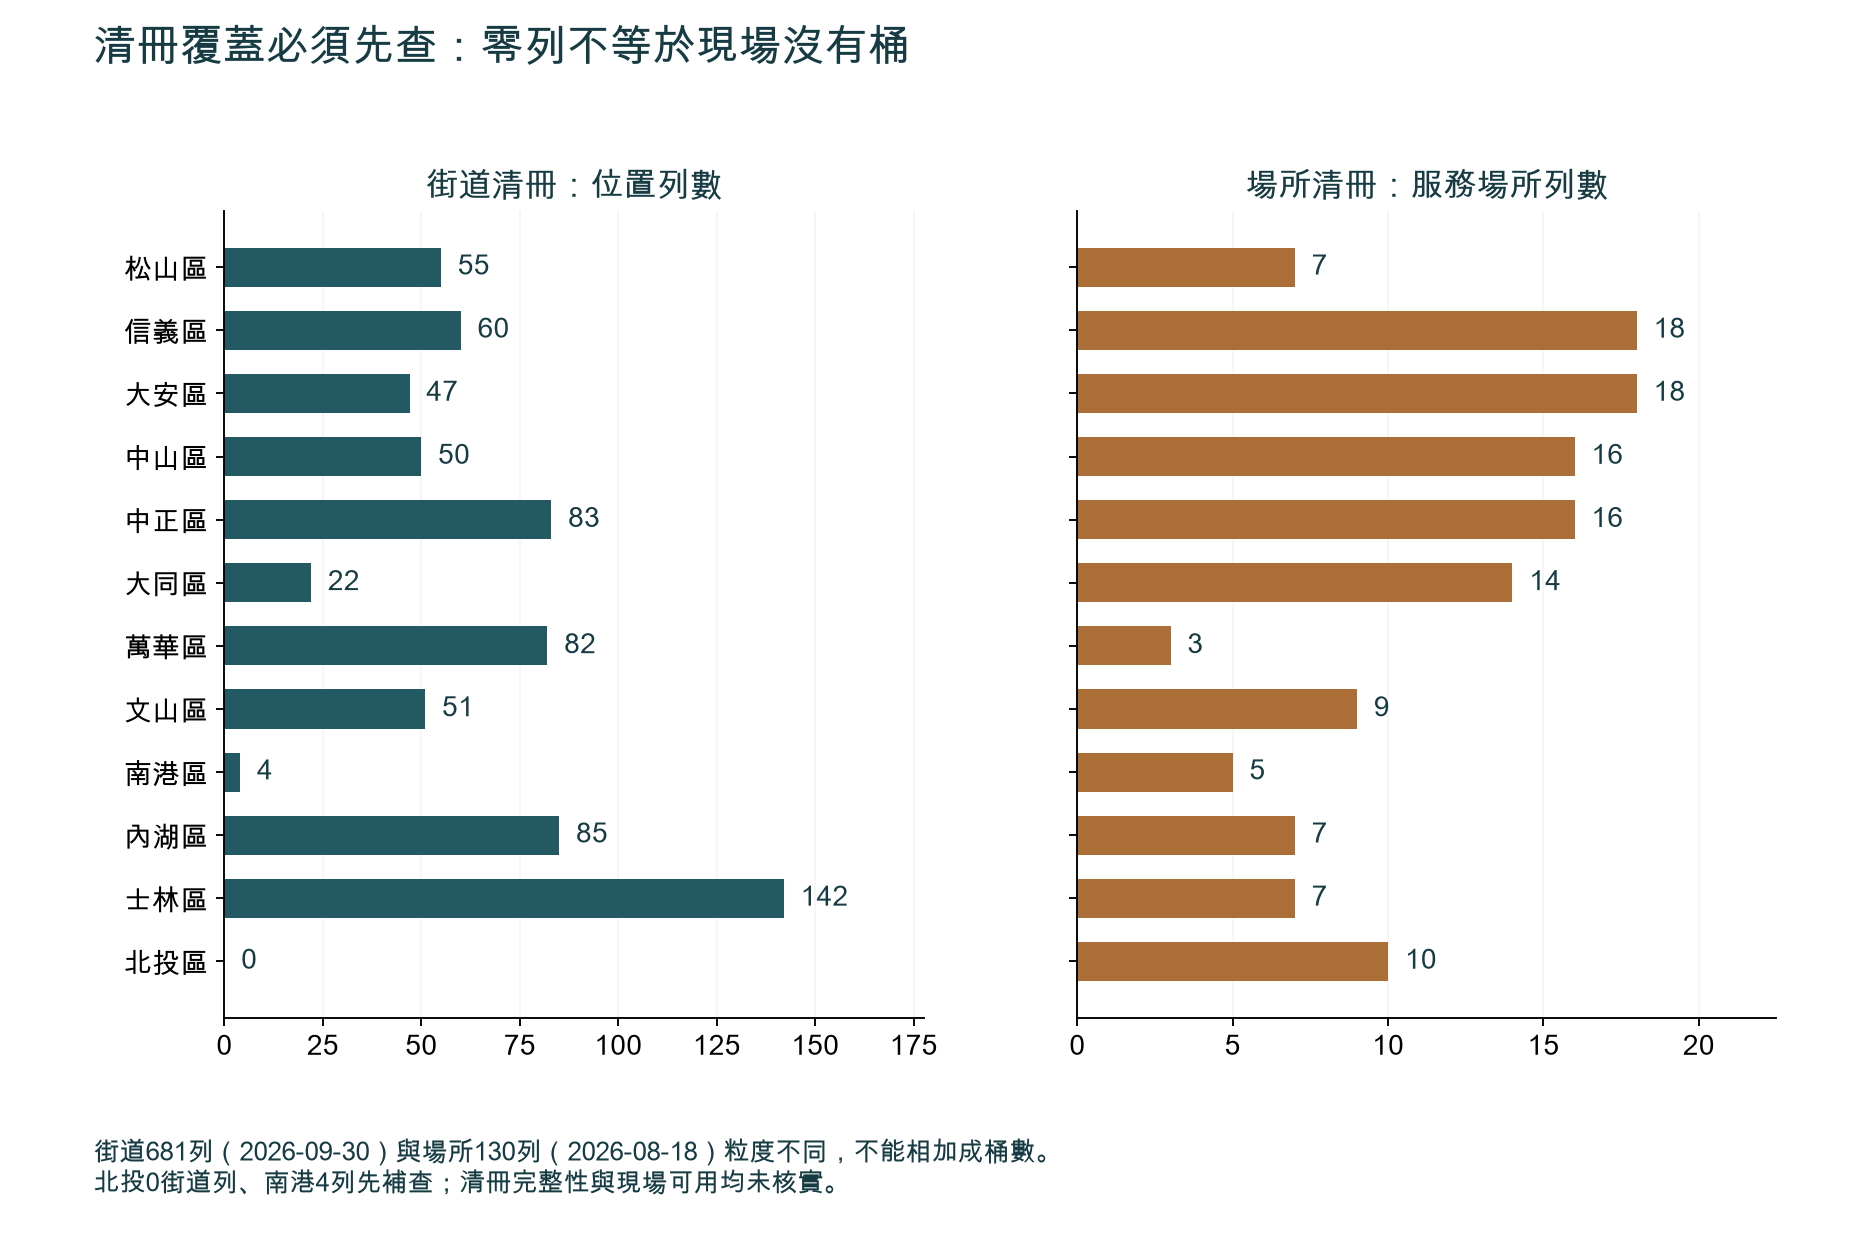

In [2]:
import html
headers=['來源分類','啟用有效站','已觀測站','端點活動','街道列','場所列','平日活動時段','週末活動時段']
rows=[]
for d in summary['districts']:
    rows.append([d['source_area'],d['eligible_stations'],d['observed_stations'],f"{d['events']:,}",d['street_rows'],d['venue_rows'],f"{d['weekday_peak_hour']}–{d['weekday_peak_hour']+1}",f"{d['weekend_peak_hour']}–{d['weekend_peak_hour']+1}"])
display(HTML('<table><thead><tr>'+''.join('<th>'+x+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(x) if x is not None else '另列，不分攤')+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>'))
from figures import create_figures
figures=create_figures()
display(Image(filename=str(figures/'district-activity.png')))
display(Image(filename=str(figures/'catalog-coverage.png')))

## 全市首輪錨點與敏感度

每區3點只規定首輪訪查，並不意味其餘站點不服務；全站結果與後續工作分流均保留。空間間隔改變會影響部分候選，須透明呈現。

松山區: 捷運南京三民站(1號出口)；臺北市藝文推廣處；捷運南京復興站(5號出口)
信義區: 捷運永春站(2號出口)；松仁路95巷口；捷運象山站(2號出口)
大安區: 捷運公館站(2號出口)；捷運科技大樓站；捷運東門站(5號出口)
中山區: 捷運中山國中站；捷運行天宮站(3號出口)；林森長春路口
中正區: 中正運動中心；光華商場；捷運古亭站(2號出口)
大同區: 捷運圓山站(1號出口)；大稻埕碼頭；捷運北門站(3號出口)
萬華區: 中華桂林路口；西本願寺廣場；萬華區公所(大理街)
文山區: 捷運萬隆站(2號出口)；台北花木批發市場；景行公園
南港區: 捷運南港展覽館站(5號出口)；南港車站(市民大道)；捷運後山埤站(3號出口)
內湖區: 捷運港墘站(1號出口)；捷運文德站(2號出口)；捷運內湖站(1號出口)
士林區: 捷運芝山站(2號出口)_1；劍潭基河路口；捷運士林站(2號出口)
北投區: 捷運北投站(1號出口)；捷運奇岩站(三合街)；北投運動中心
臺大公館校區: 臺大第一活動中心西南側；臺大新體育館東南側；臺大社科院西側
Sensitivity changes:
信義區 500 events 2 of 3 retained
萬華區 500 events 2 of 3 retained
文山區 150 events 2 of 3 retained
文山區 500 events 2 of 3 retained
臺大公館校區 500 events 2 of 3 retained


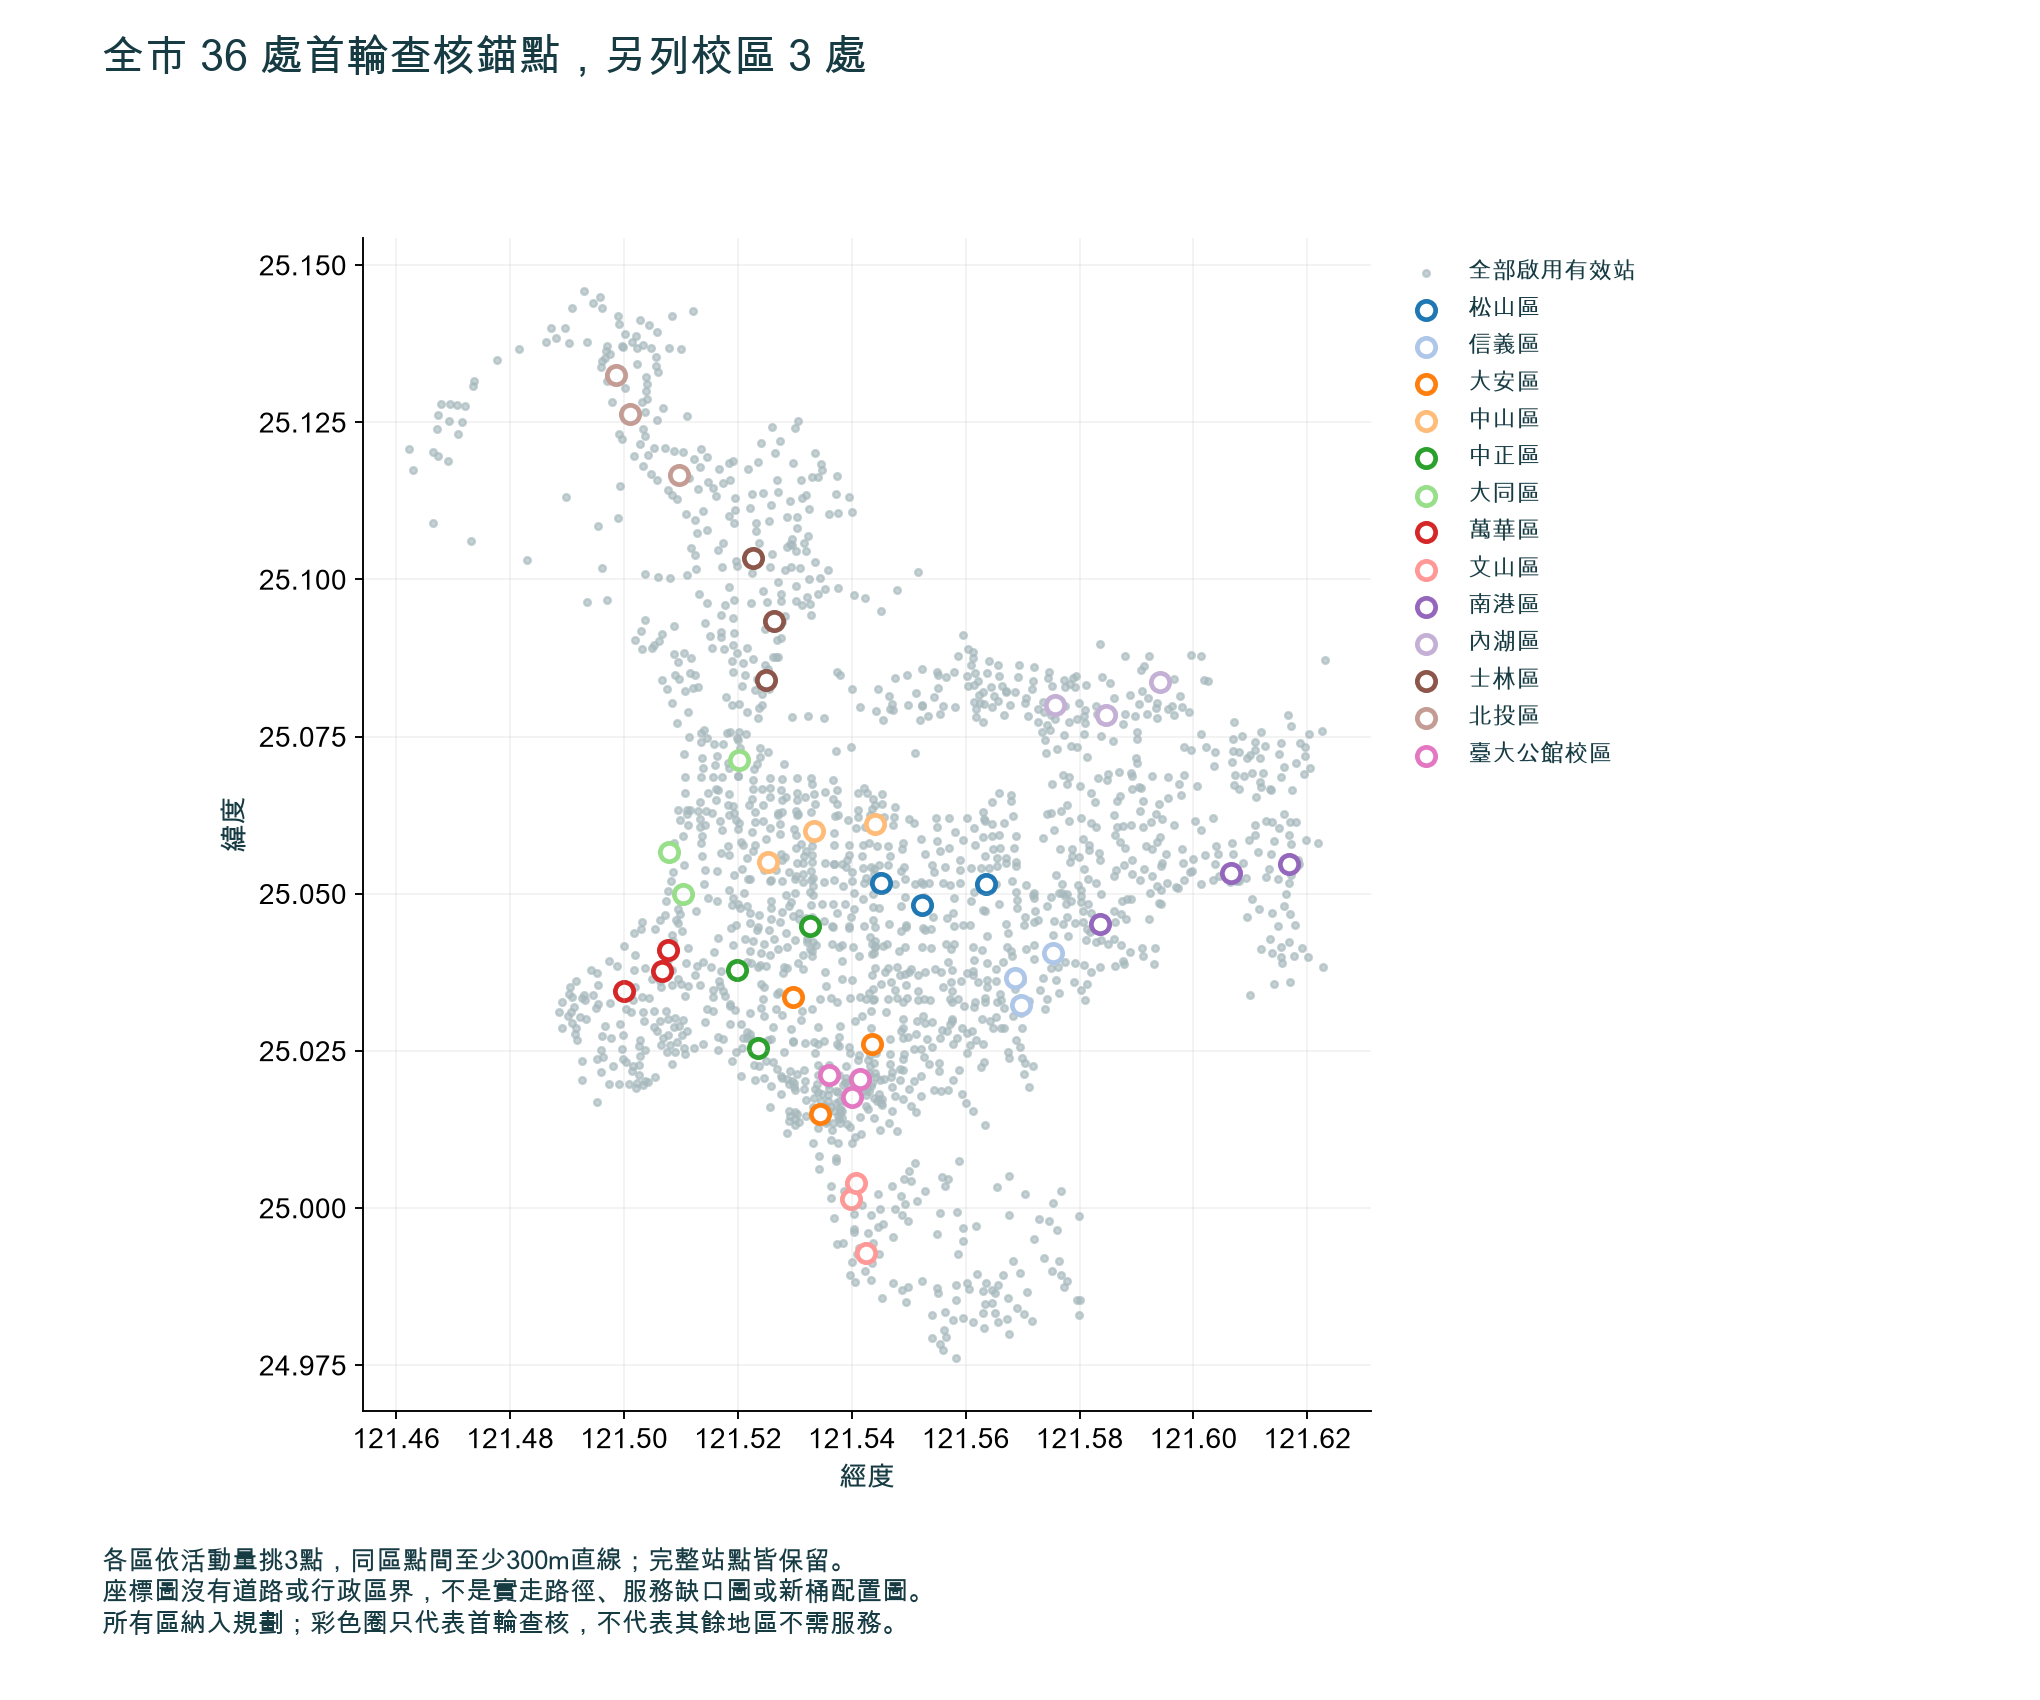

In [3]:
for d in summary['districts']:
    names=[r['name'] for r in summary['candidates'] if r['source_area']==d['source_area']]
    print(d['source_area']+': '+'；'.join(names))
print('Sensitivity changes:')
for r in summary['sensitivity']:
    if r['retained_of_primary3']<3:print(r['source_area'],r['minimum_separation_m'],r['activity_basis'],r['retained_of_primary3'],'of 3 retained')
display(Image(filename=str(figures/'citywide-context.png')))

## 轉成全市工作安排

市級統一資料欄位、品質門檻與跨機關決策，12區清潔隊依實際權責查核、區公所協助區里協調；場地及交通單位依各案管理界面確認。完整政府工作包見`government/government-plan.md`。

首輪建議每區3點×3日×兩時窗×15分鐘，共18站次／4.5純觀察小時；全12區216站次／54小時。校區另18站次／4.5小時。未含交通、整理、陪同、重訪；未安排人力或獲機關承諾。平日與週末按各區活動峰值安排，對照10–11時；遇峰值同時則改14–15時。

所有區都納入資料盤點與服務查核。現勘後按確認問題分為既有資訊／可達性、維護清運、待補資料、具體配置條件四路，並可維持現況。交通弱訊號區仍須透過公車、行人、商圈及實際垃圾觀察補覆蓋。不存在已核准的增桶數、預算、試辦成效或機關承諾。

## 主要限制

月份缺日／異常日、跨期站名、來源無旅程ID、未知站點、無完整行政區界、垃圾及路網未測量、公車逐站人流尚缺，均保留。本版是城市級活動代理與行政規劃，不是全市垃圾量測。